## Load the data

In [20]:
import json
import numpy as np

with open("tallinn_osrm_matrix.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Number of locations, including depot
n = 5

# Location names
names = [point["name"] for point in data["points"][:n]]

# Distance matrix in kilometres
distances = np.array(data["distances"], dtype=float)[:n, :n] / 1000
for i in range(len(distances)):
    for j in range(i):
        distances[i][j]=distances[j][i]
        
print("Locations:")
for i, name in enumerate(names):
    print(f"{i}: {name}")

print("\nDistance matrix (km):")
print(np.round(distances, 2))

Locations:
0: Omniva Pallasti (depot)
1: Kadriorg President's Office
2: Shaurma Kebab Punane
3: Kultuurikatel
4: Patarei Prison

Distance matrix (km):
[[0.   2.68 2.77 3.94 5.14]
 [2.68 0.   4.47 3.22 4.42]
 [2.77 4.47 0.   6.13 7.33]
 [3.94 3.22 6.13 0.   1.39]
 [5.14 4.42 7.33 1.39 0.  ]]


## Optimal route with classical algorithm

In [21]:
from itertools import permutations

def calculate_distance(route, distances):
    return sum(
        distances[route[i], route[i + 1]]
        for i in range(len(route) - 1)
    )

best_distance = float("inf")
best_route = None

# Depot (0) is fixed at the start and end
for order in permutations(range(1, n)):
    route = (0,) + order + (0,)

    total_distance = calculate_distance(route, distances)

    if total_distance < best_distance:
        best_distance = total_distance
        best_route = route

print("Optimal route:")
print(" → ".join(names[i] for i in best_route))
print(best_route)

print(f"\nMinimum distance: {best_distance:.2f} km")

Optimal route:
Omniva Pallasti (depot) → Shaurma Kebab Punane → Kadriorg President's Office → Kultuurikatel → Patarei Prison → Omniva Pallasti (depot)
(0, 2, 1, 3, 4, 0)

Minimum distance: 16.98 km


## Visualization

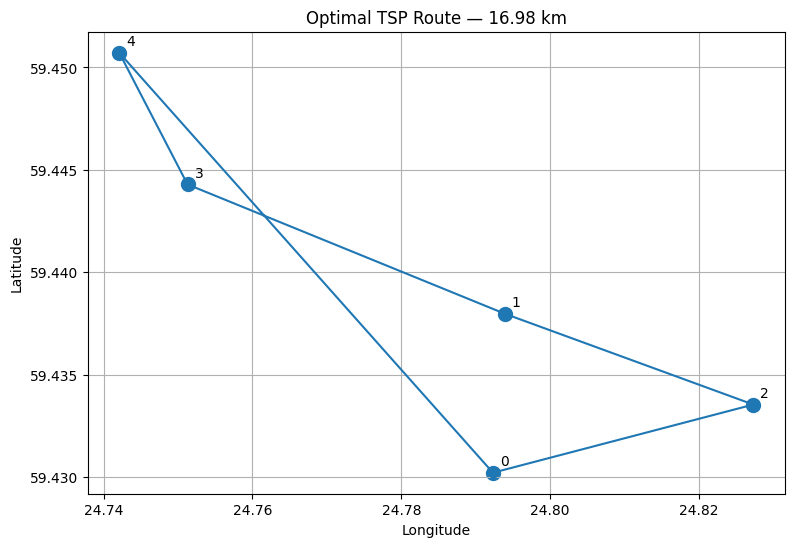

In [22]:
import matplotlib.pyplot as plt

# Coordinates of selected locations
latitudes = [p["lat"] for p in data["points"][:n]]
longitudes = [p["lon"] for p in data["points"][:n]]

plt.figure(figsize=(9, 6))

# Draw locations
plt.scatter(longitudes, latitudes, s=100)

# Draw route
route_lons = [longitudes[i] for i in best_route]
route_lats = [latitudes[i] for i in best_route]

plt.plot(route_lons, route_lats, marker="o")

for i, name in enumerate(names):
    plt.annotate(str(i), (longitudes[i], latitudes[i]),
                 xytext=(5, 5), textcoords="offset points")

plt.title(f"Optimal TSP Route — {best_distance:.2f} km")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

## TSP formulation as QUBO

In [23]:
from qiskit_optimization import QuadraticProgram

n = 5
m = n - 1

qp = QuadraticProgram("Omniva_TSP")

m = n - 1  # Number of delivery locations

# Binary variables: x[i, p] = 1 if location i is visited at position p
for i in range(1, n):
    for p in range(m):
        qp.binary_var(name=f"x_{i}_{p}")

# Objective: minimize total driving distance
linear = {}
quadratic = {}

# Depot -> first delivery
for i in range(1, n):
    linear[f"x_{i}_0"] = distances[0, i]

# Last delivery -> depot
for i in range(1, n):
    name = f"x_{i}_{m-1}"
    linear[name] = linear.get(name, 0) + distances[i, 0]

# Distances between consecutive deliveries
for p in range(m - 1):
    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                quadratic[(f"x_{i}_{p}", f"x_{j}_{p+1}")] = distances[i, j]

qp.minimize(linear=linear, quadratic=quadratic)

# Every location must be visited exactly once
for i in range(1, n):
    qp.linear_constraint(
        linear={f"x_{i}_{p}": 1 for p in range(m)},
        sense="==",
        rhs=1,
        name=f"visit_{i}"
    )

# Every route position must contain exactly one location
for p in range(m):
    qp.linear_constraint(
        linear={f"x_{i}_{p}": 1 for i in range(1, n)},
        sense="==",
        rhs=1,
        name=f"position_{p}"
    )

print(qp.prettyprint())

Problem name: Omniva_TSP

Minimize
  4.471*x_1_0*x_2_1 + 3.221*x_1_0*x_3_1 + 4.42*x_1_0*x_4_1 + 4.471*x_1_1*x_2_0
  + 4.471*x_1_1*x_2_2 + 3.221*x_1_1*x_3_0 + 3.221*x_1_1*x_3_2 + 4.42*x_1_1*x_4_0
  + 4.42*x_1_1*x_4_2 + 4.471*x_1_2*x_2_1 + 4.471*x_1_2*x_2_3 + 3.221*x_1_2*x_3_1
  + 3.221*x_1_2*x_3_3 + 4.42*x_1_2*x_4_1 + 4.42*x_1_2*x_4_3 + 4.471*x_1_3*x_2_2
  + 3.221*x_1_3*x_3_2 + 4.42*x_1_3*x_4_2 + 6.134*x_2_0*x_3_1 + 7.334*x_2_0*x_4_1
  + 6.134*x_2_1*x_3_0 + 6.134*x_2_1*x_3_2 + 7.334*x_2_1*x_4_0
  + 7.334*x_2_1*x_4_2 + 6.134*x_2_2*x_3_1 + 6.134*x_2_2*x_3_3
  + 7.334*x_2_2*x_4_1 + 7.334*x_2_2*x_4_3 + 6.134*x_2_3*x_3_2
  + 7.334*x_2_3*x_4_2 + 1.387*x_3_0*x_4_1 + 1.387*x_3_1*x_4_0
  + 1.387*x_3_1*x_4_2 + 1.387*x_3_2*x_4_1 + 1.387*x_3_2*x_4_3
  + 1.387*x_3_3*x_4_2 + 2.676*x_1_0 + 2.676*x_1_3 + 2.768*x_2_0 + 2.768*x_2_3
  + 3.937*x_3_0 + 3.937*x_3_3 + 5.136*x_4_0 + 5.136*x_4_3

Subject to
  Linear constraints (8)
    x_1_0 + x_1_1 + x_1_2 + x_1_3 == 1  'visit_1'
    x_2_0 + x_2_1 + x_2_2 + x_

## QUBO -> Ising Hamiltonian

In [24]:
from qiskit_optimization.converters import QuadraticProgramToQubo

# Convert constrained optimization problem to QUBO
penalty = 100

converter = QuadraticProgramToQubo(penalty=penalty)
qubo = converter.convert(qp)

# Convert QUBO to Ising Hamiltonian
H_raw, offset = qubo.to_ising()

# Scale Hamiltonian
H = (H_raw / penalty).simplify()

print("QUBO variables:", qubo.get_num_binary_vars())
print("Qubits:", H.num_qubits)
print("Hamiltonian terms:", len(H))

QUBO variables: 16
Qubits: 16
Hamiltonian terms: 100


## Check QUBO

In [25]:
import numpy as np

# Optimal route without depot
delivery_order = best_route[1:-1]

# Encode route as binary variables
assignment = {
    f"x_{i}_{p}": int(delivery_order[p] == i)
    for i in range(1, n)
    for p in range(m)
}

x = np.array([
    assignment[var.name]
    for var in qp.variables
])

print("Optimal route:", best_route)
print("Classical distance:", best_distance)
print("QP objective:", qp.objective.evaluate(x))
print("QUBO objective:", qubo.objective.evaluate(x))
print("Constraints satisfied:", qp.is_feasible(x))

Optimal route: (0, 2, 1, 3, 4, 0)
Classical distance: 16.983
QP objective: 16.983
QUBO objective: 16.982999999999947
Constraints satisfied: True


## QAOA circuit

In [26]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit import transpile

REPS = 2  # Start with one QAOA layer

ansatz = QAOAAnsatz(
    cost_operator=H,
    reps=REPS
)

# Transpile to basic gates for statevector simulation
ansatz = transpile(
    ansatz,
    basis_gates=["h", "rx", "rz", "cx"],
    optimization_level=1
)

print("Qubits:", ansatz.num_qubits)
print("Parameters:", ansatz.num_parameters)
print("Circuit depth:", ansatz.depth())

Qubits: 16
Parameters: 4
Circuit depth: 134


## QAOA optimization

In [27]:
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize
import numpy as np

# Hamiltonian used for optimization
H_matrix = H

def qaoa_cost(params):
    # Assign gamma and beta values
    circuit = ansatz.assign_parameters(params)

    # Simulate quantum circuit
    state = Statevector.from_instruction(circuit)

    # Calculate expected energy
    energy = np.real(state.expectation_value(H_matrix))

    return energy

# Initial parameters
initial_params = np.full(ansatz.num_parameters, 0.5)

# Optimize QAOA parameters
result = minimize(
    qaoa_cost,
    initial_params,
    method="COBYLA",
    options={"maxiter": 200}
)

print("Optimization finished!")
print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)
print("Iterations:", result.nfev)

Optimization finished!
Optimal parameters: [ 0.51159541  2.17486314  0.27291698 -0.03728184]
Minimum energy: -12.791024106987264
Iterations: 200


## QAOA result

In [28]:
from itertools import permutations
from qiskit.quantum_info import Statevector
import numpy as np

# 1. Simulate the optimized QAOA circuit
optimized_circuit = ansatz.assign_parameters(result.x)
state = Statevector.from_instruction(optimized_circuit)
probabilities = state.probabilities()

# 2. Generate all valid TSP routes
valid_routes = []

for order in permutations(range(1, n)):
    route = (0,) + order + (0,)

    # Encode the route into binary variables
    assignment = {
        f"x_{i}_{p}": int(order[p] == i)
        for i in range(1, n)
        for p in range(m)
    }

    bits = np.array([
        assignment[var.name]
        for var in qp.variables
    ])

    # Convert binary variables to statevector index
    index = sum(int(bit) << i for i, bit in enumerate(bits))

    probability = probabilities[index]
    distance = calculate_distance(route, distances)

    valid_routes.append((route, distance, probability))

# 3. Calculate total valid-route probability
valid_probability = sum(
    probability
    for route, distance, probability in valid_routes
)

# 4. Calculate optimal-route probability
optimal_probability = sum(
    probability
    for route, distance, probability in valid_routes
    if np.isclose(distance, best_distance)
)

# 5. Find the most probable VALID route
best_qaoa_route = max(
    valid_routes,
    key=lambda item: item[2]
)

# 6. Print results
print("=== QAOA RESULTS ===")
print(f"Classical optimum: {best_distance:.3f} km")
print(f"Valid route probability: {valid_probability * 100:.4f}%")
print(f"Optimal route probability: {optimal_probability * 100:.4f}%")

print("\nMost probable valid route:")
print(" -> ".join(map(str, best_qaoa_route[0])))
print(f"Distance: {best_qaoa_route[1]:.3f} km")
print(f"Probability: {best_qaoa_route[2] * 100:.4f}%")

=== QAOA RESULTS ===
Classical optimum: 16.983 km
Valid route probability: 3.9626%
Optimal route probability: 0.6691%

Most probable valid route:
0 -> 4 -> 3 -> 1 -> 2 -> 0
Distance: 16.983 km
Probability: 0.1674%


## Average distance among valid routes, weighted by their QAOA probabilities

In [29]:
weighted_distance = sum(
    distance * probability
    for route, distance, probability in valid_routes
)

average_valid_distance = weighted_distance / valid_probability

print("=== ROUTE QUALITY ===")
print(f"Classical optimum: {best_distance:.3f} km")
print(f"Average valid route distance: {average_valid_distance:.3f} km")
print(f"Difference: {average_valid_distance - best_distance:.3f} km")

=== ROUTE QUALITY ===
Classical optimum: 16.983 km
Average valid route distance: 20.714 km
Difference: 3.731 km


## FIND THE BEST ROUTE FROM QAOA MEASUREMENTS

In [30]:
from qiskit.quantum_info import Statevector
import numpy as np

shots = 10_000

# Use the best previously found REPS=2 parameters
circuit = ansatz.assign_parameters(result.x)

state = Statevector.from_instruction(circuit)

# Simulate measurements
state.seed(42)
counts = state.sample_counts(shots=shots)

best_sampled_route = None
best_sampled_distance = float("inf")
valid_measurements = 0

for bitstring, count in counts.items():

    # Convert Qiskit bitstring to QUBO variable order
    bits = np.array([int(b) for b in bitstring[::-1]])

    # Ignore invalid routes
    if not qp.is_feasible(bits):
        continue

    valid_measurements += count

    # Decode route
    order = []

    for p in range(m):
        for i in range(1, n):
            var_name = f"x_{i}_{p}"
            var_index = qp.variables_index[var_name]

            if bits[var_index] == 1:
                order.append(i)
                break

    route = (0,) + tuple(order) + (0,)
    distance = calculate_distance(route, distances)

    if distance < best_sampled_distance:
        best_sampled_distance = distance
        best_sampled_route = route

print("=== BEST SAMPLED QAOA ROUTE ===")
print("Shots:", shots)
print("Valid measurements:", valid_measurements)
print("Best sampled route:", best_sampled_route)
print(f"Distance: {best_sampled_distance:.3f} km")
print(f"Classical optimum: {best_distance:.3f} km")

=== BEST SAMPLED QAOA ROUTE ===
Shots: 10000
Valid measurements: 394
Best sampled route: (0, 4, 3, 1, 2, 0)
Distance: 16.983 km
Classical optimum: 16.983 km
